In [1]:

import os
import pandas as pd

print(os.listdir('/content'))


['.config', 'retail_sales_dataset.csv', 'sample_data']


In [2]:

df = pd.read_csv('/content/retail_sales_dataset.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/retail_sales_dataset.csv')

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Number of rows and columns: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:

print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Data Types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Rows:
0


In [5]:

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate descriptive statistics
summary = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median(),
    "Mode": numeric_df.mode().iloc[0],
    "Standard Deviation": numeric_df.std()
})

display(summary.round(2))


,Mean,Median,Mode,Standard Deviation
Transaction ID,500.50,500.5,1.0,288.82
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


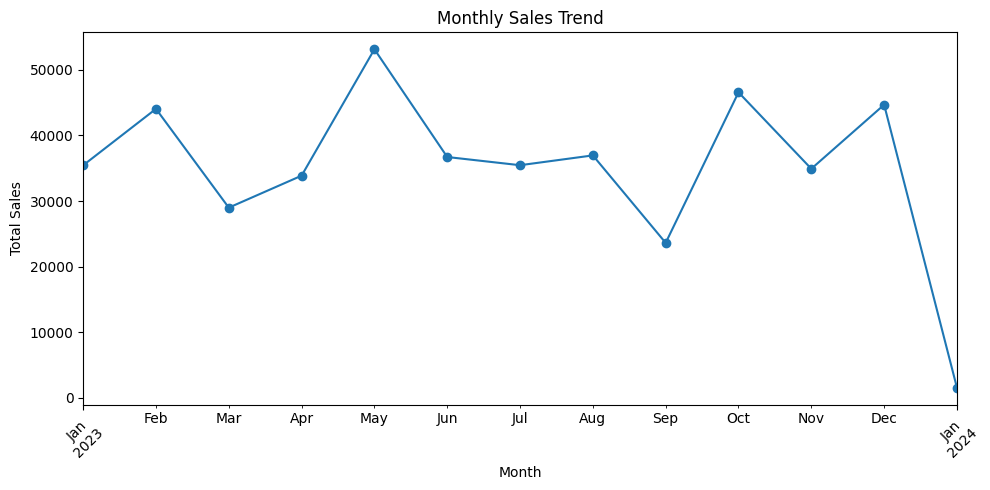

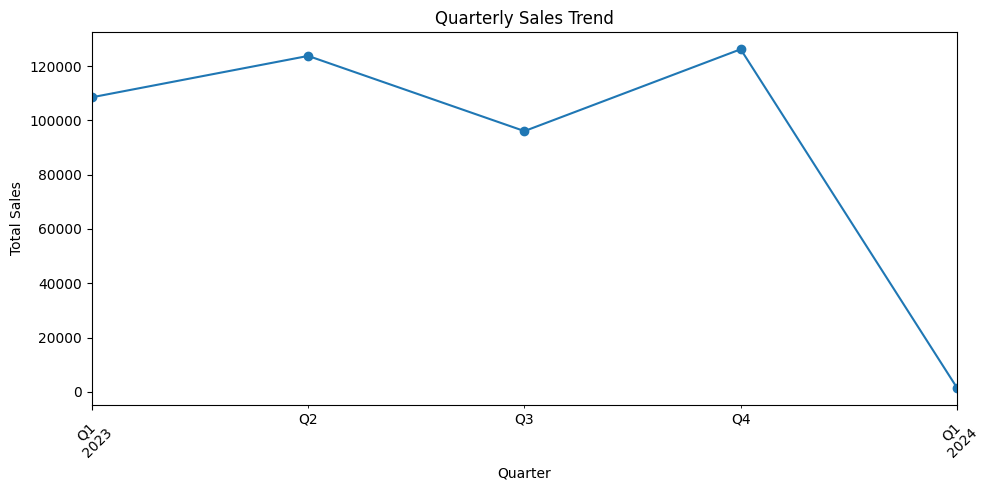

In [6]:

# Convert Date column to date format
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Remove rows with missing dates or sales amounts
sales_df = df.dropna(subset=['Date', 'Total Amount']).copy()

# Monthly sales
monthly_sales = (
    sales_df.set_index('Date')['Total Amount']
    .resample('MS')
    .sum()
)

plt.figure(figsize=(10, 5))
monthly_sales.plot(marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Quarterly sales
quarterly_sales = (
    sales_df.set_index('Date')['Total Amount']
    .resample('QS')
    .sum()
)

plt.figure(figsize=(10, 5))
quarterly_sales.plot(marker='o')
plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


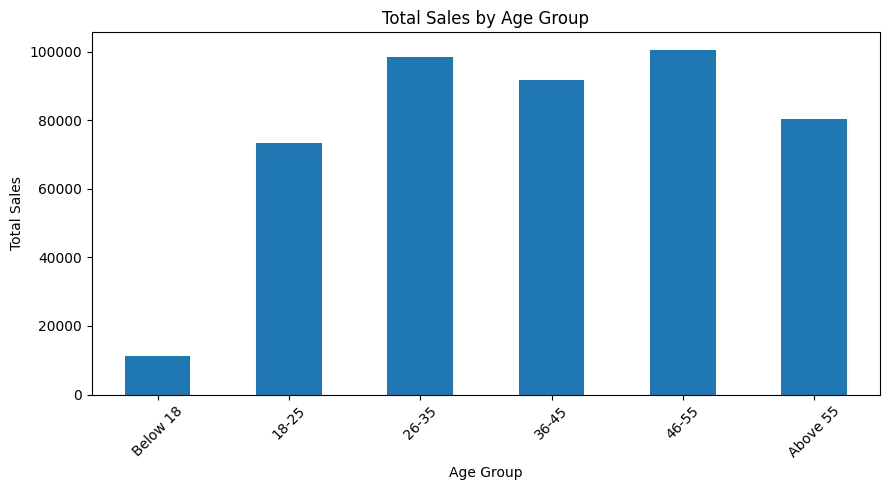

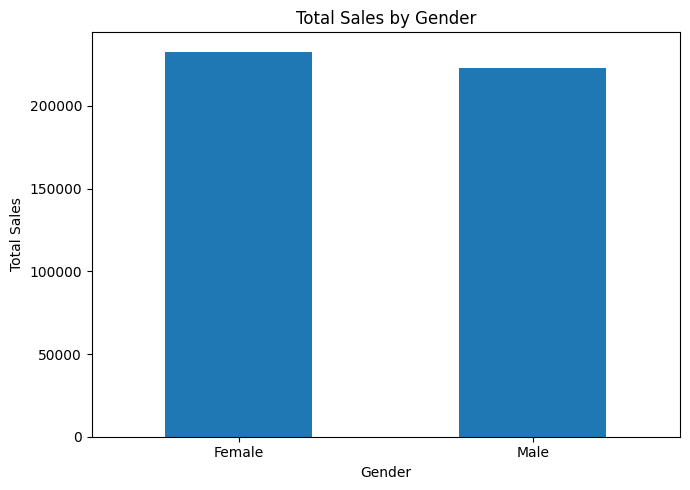

In [7]:

# Age group analysis
age_df = df.dropna(subset=['Age', 'Gender', 'Total Amount']).copy()

# Create age groups
age_df['Age Group'] = pd.cut(
    age_df['Age'],
    bins=[0, 18, 25, 35, 45, 55, 100],
    labels=['Below 18', '18-25', '26-35', '36-45', '46-55', 'Above 55'],
    include_lowest=True
)

# Sales by age group
age_sales = age_df.groupby('Age Group', observed=False)['Total Amount'].sum()

plt.figure(figsize=(9, 5))
age_sales.plot(kind='bar')
plt.title('Total Sales by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Observation: Add a Text cell below the chart and write
# which age group has the highest sales based on your chart.


# Sales by gender
gender_sales = age_df.groupby('Gender')['Total Amount'].sum()

plt.figure(figsize=(7, 5))
gender_sales.plot(kind='bar')
plt.title('Total Sales by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Observation: Add a Text cell below the chart and write
# which gender has the highest sales based on your chart.


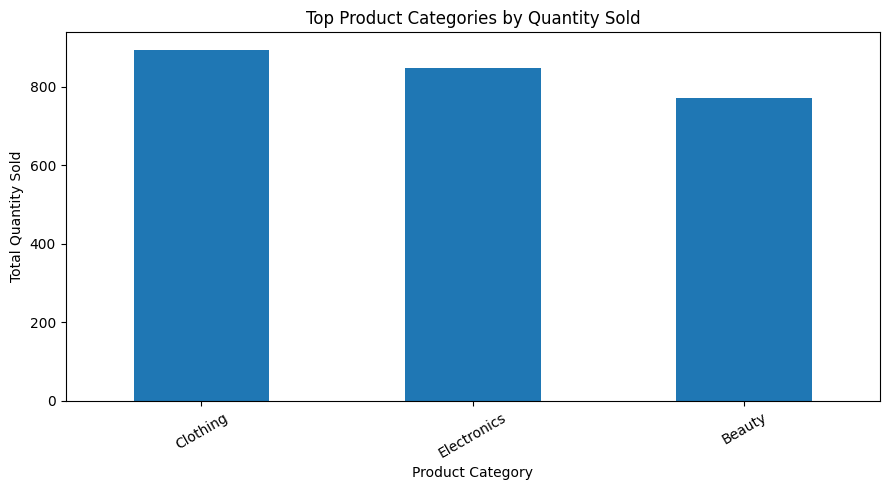

In [8]:

# Find the top 10 products by quantity sold
top_products = (
    df.groupby('Product Category')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(9, 5))
top_products.plot(kind='bar')
plt.title('Top Product Categories by Quantity Sold')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


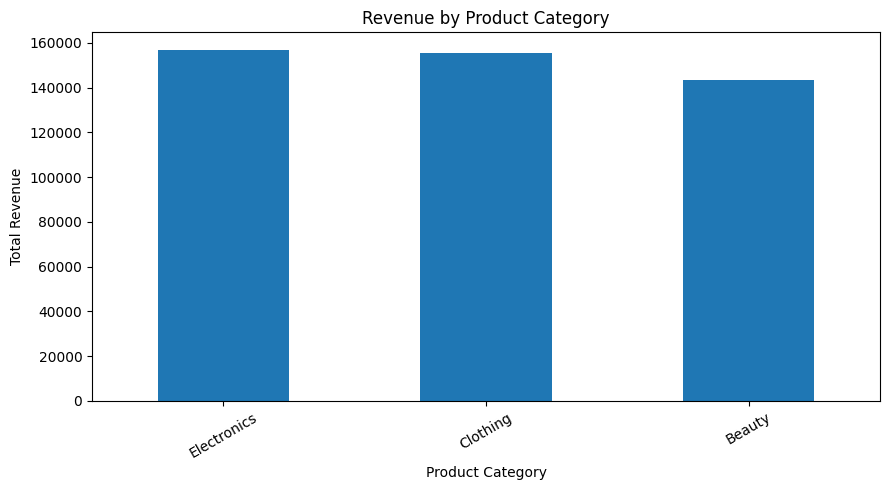

In [9]:

# Calculate revenue for each product category
category_revenue = (
    df.groupby('Product Category')['Total Amount']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
category_revenue.plot(kind='bar')
plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


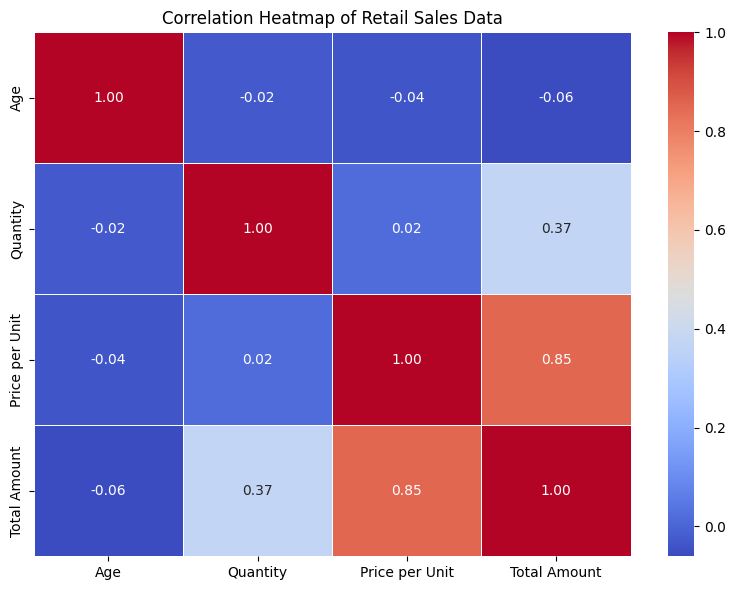

In [10]:

import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns
numeric_df = df[
    ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
]

# Calculate correlation
correlation = numeric_df.corr()

# Draw heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Retail Sales Data')
plt.tight_layout()
plt.show()


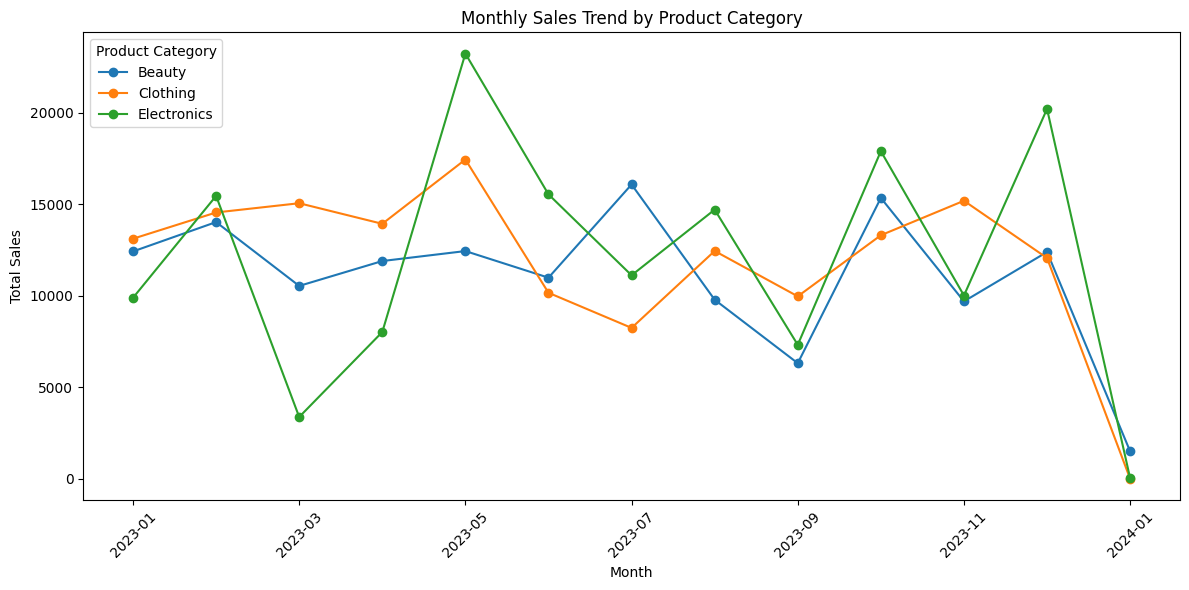

In [11]:

import pandas as pd
import matplotlib.pyplot as plt

# Prepare the data
sales_df = df.dropna(
    subset=['Date', 'Product Category', 'Total Amount']
).copy()

sales_df['Date'] = pd.to_datetime(
    sales_df['Date'], errors='coerce'
)
sales_df = sales_df.dropna(subset=['Date'])

# Extract month
sales_df['Month'] = sales_df['Date'].dt.to_period('M').astype(str)

# Calculate monthly sales for each category
monthly_category = sales_df.pivot_table(
    index='Month',
    columns='Product Category',
    values='Total Amount',
    aggfunc='sum',
    fill_value=0
)

# Plot the chart
monthly_category.plot(figsize=(12, 6), marker='o')

plt.title('Monthly Sales Trend by Product Category')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.legend(title='Product Category')
plt.tight_layout()
plt.show()


## 9. Conclusion

Exploratory Data Analysis (EDA) was performed on the Retail Sales Dataset using Python, Pandas, Matplotlib, and Seaborn. The dataset was analyzed to understand sales trends, customer demographics, product category performance, and relationships between numerical variables.

Monthly and quarterly sales trends were visualized to understand changes in sales over time. Age group and gender analysis were performed to explore customer purchasing patterns. Product category sales and revenue were compared using bar charts, and a correlation heatmap was used to examine relationships between numerical variables. An additional monthly sales trend by product category visualization was also created.

This analysis helps identify sales patterns and supports better business decision-making.

## 10. Business Recommendations

1. **Improve inventory planning:** Keep sufficient stock of categories that generate higher sales and monitor slower-selling categories.

2. **Understand customer preferences:** Use age group and gender analysis to understand customer purchasing patterns and plan suitable marketing campaigns.

3. **Monitor sales trends:** Review monthly and quarterly sales regularly to identify changes in performance and plan promotions during weaker sales periods.

4. **Increase category revenue:** Compare revenue across product categories and explore ways to improve the performance of lower-revenue categories.

5. **Use data for decision-making:** Update and analyze sales data regularly to support inventory, marketing, and business planning.

## 11. Tools and Technologies Used

- Python
- Pandas
- Matplotlib
- Seaborn
- Google Colab
- Retail Sales Dataset

## 12. Final Outcome

The project demonstrates how exploratory data analysis and data visualization can help transform retail sales data into useful business insights.
